<a href="https://colab.research.google.com/github/meliaaputr9/UTS-Data-Mining_2404010012/blob/main/UTS_DATA_MINING_KLASIFIKASI_ANGGUR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
sns.set_style("whitegrid")

PATH_TRAIN  = "data_training.csv"
PATH_TEST   = "data_testing.csv"
PATH_FORMAT = "hasilprediksi_3digitNIMterakhir.csv"
NIM3        = "012"

## 1. Persiapan Data
Memuat dataset training (berisi fitur, `quality`, dan `Id`) dan dataset testing (berisi fitur dan `Id`, tanpa `quality`).

In [2]:
train = pd.read_csv(PATH_TRAIN)
test  = pd.read_csv(PATH_TEST)

print("Shape training:", train.shape)
print("Shape testing :", test.shape)
display(train.head())
display(test.head())
train.info()

Shape training: (857, 13)
Shape testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB


**Interpretasi:** Interpretasi: Data training berisi 857 baris dan 13 kolom (11 fitur kimia, quality, dan Id), sedangkan data testing berisi 286 baris dan 12 kolom (tanpa quality). Semua kolom fitur bertipe numerik. Kolom Id hanya pengenal baris, bukan fitur, sehingga tidak dipakai untuk melatih model.

Jumlah fitur: 11
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


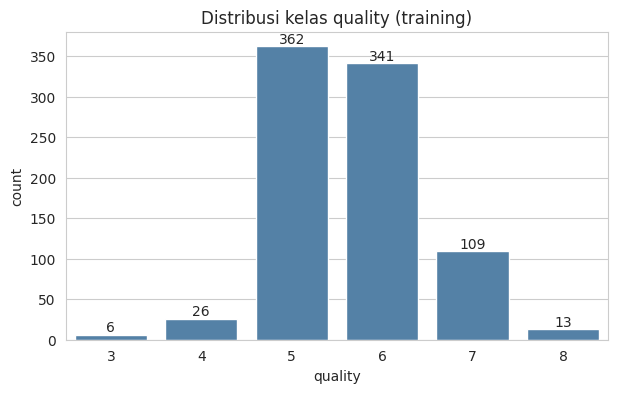

quality
3    0.007
4    0.030
5    0.422
6    0.398
7    0.127
8    0.015
Name: proportion, dtype: float64


In [3]:
TARGET = "quality"
ID_COL = [c for c in train.columns if c.lower() == "id"][0]
FEATURES = [c for c in train.columns if c not in (TARGET, ID_COL)]
print("Jumlah fitur:", len(FEATURES))
print(FEATURES)
assert set(FEATURES) <= set(test.columns), "Kolom fitur di testing tidak sama dengan training"

plt.figure(figsize=(7,4))
ax = sns.countplot(x=TARGET, data=train, color="steelblue")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribusi kelas quality (training)")
plt.show()
print(train[TARGET].value_counts(normalize=True).sort_index().round(3))

**Interpretasi:** Distribusi kelas tidak seimbang. Kelas 5 (42,2%) dan kelas 6 (39,8%) menguasai sekitar 82% data. Kelas 7 sebesar 12,7%, sedangkan kelas 4 (3,0%), 8 (1,5%), dan 3 (0,7%) sangat sedikit. Karena itu evaluasi memakai accuracy dan macro-F1, split dan CV dibuat stratified, dan dicoba Random Forest dengan class_weight balanced.

## 2. Pembersihan Data
### 2.1 Missing value dan duplikat

In [4]:
print("Missing value training:\n", train.isna().sum()[train.isna().sum() > 0])
print("Missing value testing :\n", test.isna().sum()[test.isna().sum() > 0])
print("Total missing training / testing:", train.isna().sum().sum(), "/", test.isna().sum().sum())

dup = train.duplicated(subset=FEATURES + [TARGET]).sum()
print("Baris duplikat di training (abaikan Id):", dup, "(TIDAK dihapus)")
print("Id duplikat di training:", train[ID_COL].duplicated().sum())

Missing value training:
 Series([], dtype: int64)
Missing value testing :
 Series([], dtype: int64)
Total missing training / testing: 0 / 0
Baris duplikat di training (abaikan Id): 76 (TIDAK dihapus)
Id duplikat di training: 0


**Interpretasi:** Tidak ada missing value di data training maupun testing (total 0), jadi imputasi median tidak dijalankan. Ditemukan 76 baris duplikat (fitur dan quality sama, Id diabaikan), sedangkan Id tidak ada yang kembar. Duplikat tidak dihapus, karena bisa jadi merupakan sampel anggur berbeda yang kebetulan bernilai sama, sehingga tetap mencerminkan distribusi data.

In [5]:
# Imputasi median (hanya berjalan jika ada missing; median dihitung dari training agar tidak bocor)
medians = train[FEATURES].median()
if train[FEATURES].isna().any().any():
    train[FEATURES] = train[FEATURES].fillna(medians)
if test[FEATURES].isna().any().any():
    test[FEATURES] = test[FEATURES].fillna(medians)

# Duplikat tidak dihapus
print("Baris training:", len(train))

Baris training: 857


### 2.2 Statistik deskriptif, skala fitur, dan outlier

In [6]:
display(train[FEATURES].describe().T[["mean","std","min","max"]].round(4))

,mean,std,min,max
fixed acidity,8.2620,1.7020,4.6000,15.6000
volatile acidity,0.5294,0.1792,0.1200,1.5800
citric acid,0.2674,0.1951,0.0000,1.0000
residual sugar,2.5062,1.2935,0.9000,15.5000
chlorides,0.0868,0.0487,0.0120,0.6110
free sulfur dioxide,15.7830,10.3004,1.0000,68.0000
total sulfur dioxide,45.9784,31.6921,6.0000,278.0000
density,0.9967,0.0019,0.9901,1.0032
pH,3.3131,0.1521,2.7400,4.0100
sulphates,0.6567,0.1674,0.3900,2.0000


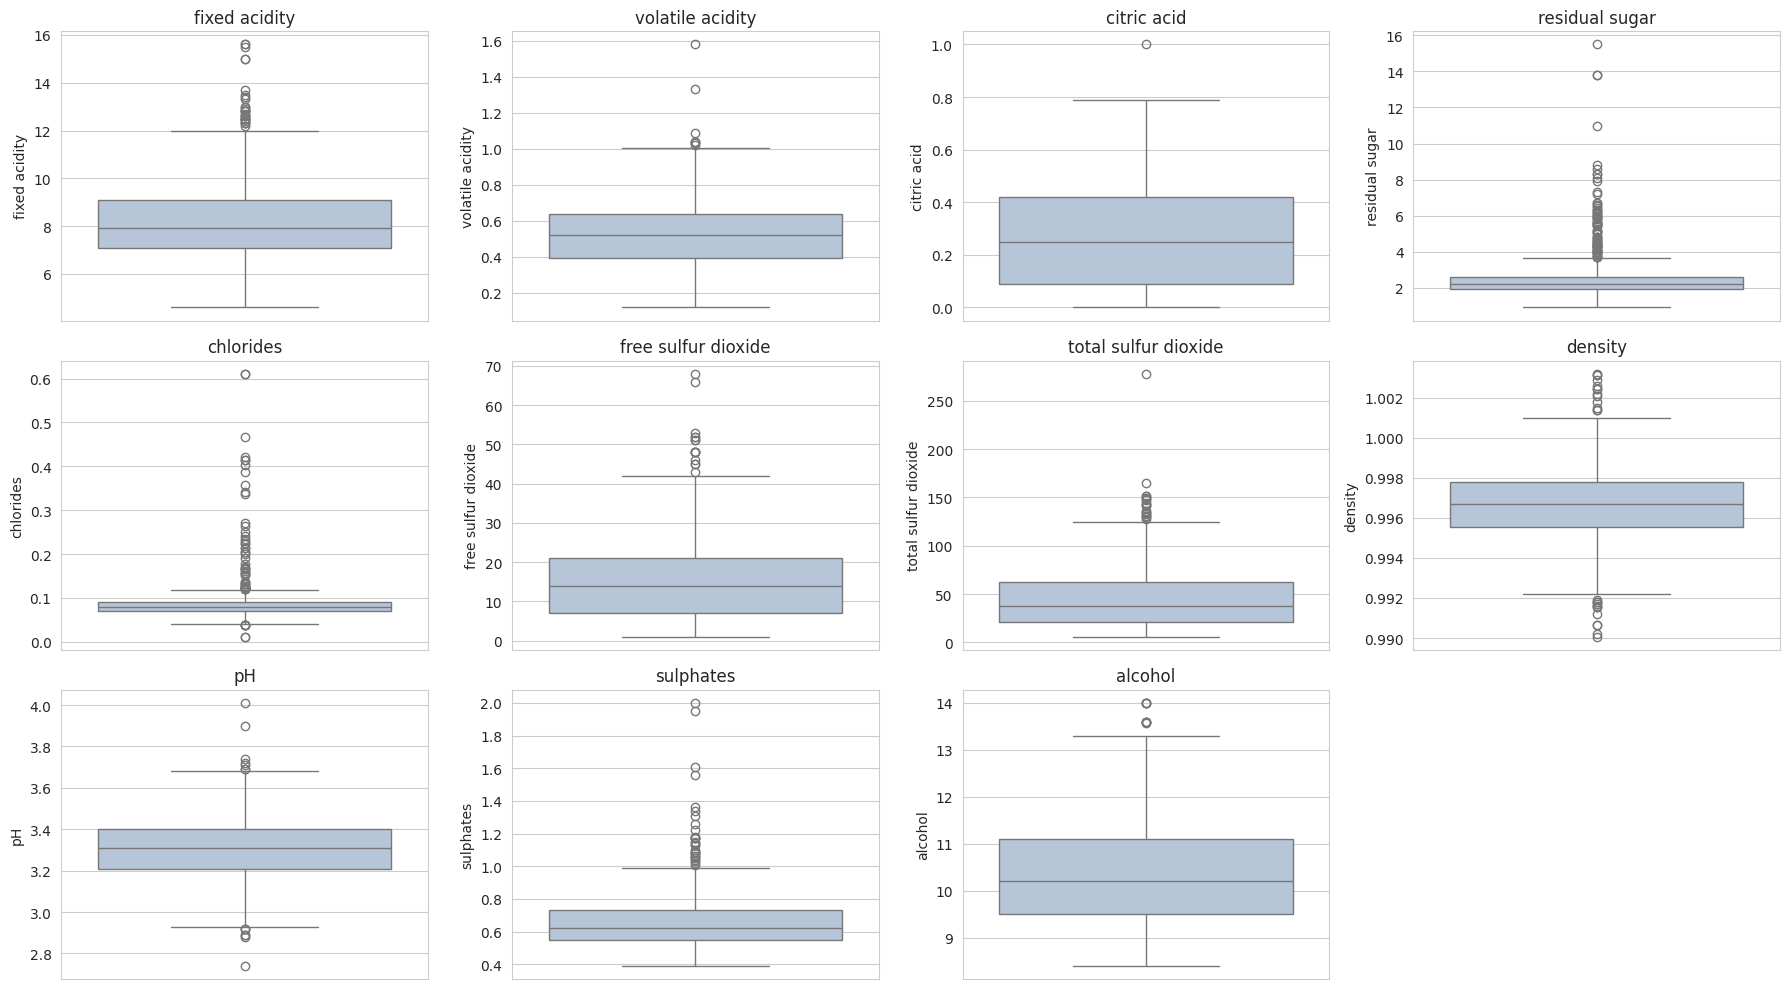

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=train[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Interpretasi:** Skala antar fitur sangat berbeda. total sulfur dioxide memiliki rata-rata 46 dan maksimum 278, free sulfur dioxide rata-rata 15,8, sedangkan density hampir konstan (rata-rata 0,9967, std 0,0019) dan chlorides rata-rata 0,087. Fitur berskala besar akan mendominasi model berbasis jarak/gradien (Logistic Regression, KNN), sehingga StandardScaler dipakai di dalam Pipeline agar tidak terjadi kebocoran data.
Beberapa fitur memiliki nilai ekstrem yang jauh dari rata-ratanya, misalnya residual sugar (maksimum 15,5 vs rata-rata 2,5), chlorides (0,611 vs 0,087), sulphates (2,0 vs 0,66), dan total sulfur dioxide (278 vs 46). Outlier tidak dihapus karena bisa merupakan variasi alami anggur dan model berbasis pohon tidak sensitif terhadapnya.

### 2.3 Korelasi antar fitur

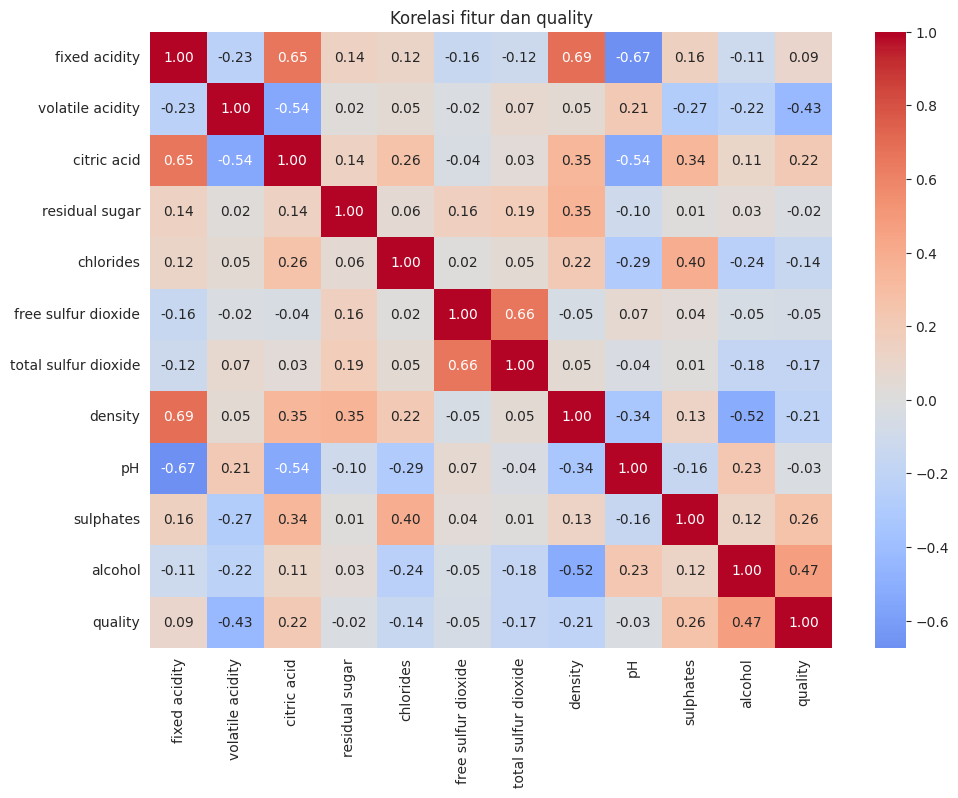

alcohol                 0.474
sulphates               0.261
citric acid             0.221
fixed acidity           0.093
residual sugar         -0.021
pH                     -0.033
free sulfur dioxide    -0.055
chlorides              -0.145
total sulfur dioxide   -0.173
density                -0.208
volatile acidity       -0.430
Name: quality, dtype: float64


In [8]:
plt.figure(figsize=(11, 8))
sns.heatmap(train[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi fitur dan quality")
plt.show()
print(train[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

**Interpretasi:** Fitur dengan korelasi positif terkuat terhadap quality adalah alcohol (0,474), lalu sulphates (0,261) dan citric acid (0,221). Korelasi negatif terkuat adalah volatile acidity (-0,430), diikuti density (-0,208) dan total sulfur dioxide (-0,173). Fitur seperti residual sugar, pH, dan free sulfur dioxide korelasinya hampir nol (kurang dari 0,06), sehingga hubungan linearnya dengan kualitas lemah.

## 3. Pembuatan Model
### 3.1 Pembagian data (hold-out)
Data dibagi 80% latih dan 20% validasi secara *stratified*. Data validasi dipakai sebagai gambaran kinerja pada data baru.

In [9]:
X = train[FEATURES]
y = train[TARGET].astype(int)

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_tr.shape, X_val.shape)

(685, 11) (172, 11)


### 3.2 Perbandingan beberapa model (Stratified 5-Fold CV)
Model yang dibandingkan: Logistic Regression (baseline), KNN, Random Forest, **Random Forest Balanced**, **Random Forest Balanced Subsample**, Extra Trees, dan Gradient Boosting.

- *Balanced*: bobot kelas dihitung dari proporsi kelas di seluruh data latih.
- *Balanced Subsample*: bobot kelas dihitung ulang di setiap bootstrap sample tiap pohon.

In [10]:
def rf(**kw):
    return Pipeline([("scaler", StandardScaler()),
                     ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **kw))])

models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    "KNN": Pipeline([("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15, weights="distance"))]),
    "Random Forest": rf(),
    "Random Forest Balanced": rf(class_weight="balanced"),
    "Random Forest Balanced Subsample": rf(class_weight="balanced_subsample"),
    "Extra Trees": Pipeline([("scaler", StandardScaler()),
        ("clf", ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("scaler", StandardScaler()),
        ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    cv = cross_validate(pipe, X_tr, y_tr, cv=skf, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({"Model": name,
                 "Accuracy (CV)": cv["test_accuracy"].mean(),
                 "Macro-F1 (CV)": cv["test_f1_macro"].mean()})
cv_result = pd.DataFrame(rows).sort_values("Accuracy (CV)", ascending=False).reset_index(drop=True)
display(cv_result.round(4))

,Model,Accuracy (CV),Macro-F1 (CV)
0,Random Forest Balanced Subsample,0.6365,0.3057
1,Extra Trees,0.6336,0.3055
2,Random Forest,0.6307,0.3092
3,Random Forest Balanced,0.6292,0.3036
4,Gradient Boosting,0.6161,0.3083
5,KNN,0.5956,0.2981
6,Logistic Regression,0.5854,0.2715


**Interpretasi:** Model berbasis pohon unggul dibanding model lain. Accuracy CV Random Forest Balanced Subsample (0,6365), Extra Trees (0,6336), Random Forest (0,6307), dan Random Forest Balanced (0,6292) hampir sama (selisih kurang dari 0,01), sedangkan Gradient Boosting 0,6161, KNN 0,5956, dan Logistic Regression terendah (0,5854). Hal ini menunjukkan hubungan fitur dengan kualitas bersifat non-linear.
Macro-F1 semua model hanya sekitar 0,27 sampai 0,31, jauh di bawah accuracy, karena kelas minoritas sulit diprediksi. Pada tahap ini versi balanced belum terbukti meningkatkan macro-F1 dibanding Random Forest biasa (0,3036 vs 0,3092).

### 3.3 Tuning hyperparameter
Random Forest di-tuning dengan `RandomizedSearchCV`. Pilihan `class_weight` (None, `balanced`, `balanced_subsample`) ikut dicari, sehingga varian balanced otomatis dipertimbangkan.
Skor yang dioptimalkan adalah **macro-F1 dan accuracy** sekaligus (`refit` memakai accuracy; ubah ke `"f1_macro"` bila ingin fokus ke kelas minoritas).

In [11]:
base = Pipeline([("scaler", StandardScaler()),
                 ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

param_dist = {
    "clf__n_estimators": [200, 300, 500, 800],
    "clf__max_depth": [None, 10, 15, 20, 30],
    "clf__min_samples_split": [2, 4, 6, 10],
    "clf__min_samples_leaf": [1, 2, 3, 4],
    "clf__max_features": ["sqrt", "log2", 0.5],
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
}

search = RandomizedSearchCV(base, param_dist, n_iter=30, cv=skf,
                            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
                            refit="accuracy",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_tr, y_tr)
print("Best params     :", search.best_params_)
print("Best CV accuracy:", round(search.best_score_, 4))
print("CV macro-F1 (best):", round(search.cv_results_["mean_test_f1_macro"][search.best_index_], 4))
best_model = search.best_estimator_

Best params     : {'clf__n_estimators': 200, 'clf__min_samples_split': 6, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': 30, 'clf__class_weight': 'balanced'}
Best CV accuracy: 0.6467
CV macro-F1 (best): 0.3447


**Interpretasi:** Hasil tuning memilih class_weight = balanced, n_estimators = 200, max_depth = 30, min_samples_split = 6, min_samples_leaf = 1, dan max_features = log2. Accuracy CV naik menjadi 0,6467 dan macro-F1 CV menjadi 0,3447, lebih tinggi dari semua model awal di tabel 3.2.

## 4. Evaluasi Model
Evaluasi pada data validasi (20%) yang tidak dipakai saat training/tuning.

### 4.1 Perbandingan RF biasa vs RF Balanced vs RF Tuning

In [12]:
cands = {
    "RF biasa": rf(),
    "RF Balanced": rf(class_weight="balanced"),
    "RF Balanced Subsample": rf(class_weight="balanced_subsample"),
    "RF Tuning": best_model,
}
rows = []
for name, m in cands.items():
    if name != "RF Tuning":
        m.fit(X_tr, y_tr)
    p = m.predict(X_val)
    rows.append({"Model": name,
                 "Accuracy (val)": accuracy_score(y_val, p),
                 "Macro-F1 (val)": f1_score(y_val, p, average="macro")})
display(pd.DataFrame(rows).round(4))

,Model,Accuracy (val),Macro-F1 (val)
0,RF biasa,0.6047,0.3548
1,RF Balanced,0.6105,0.3523
2,RF Balanced Subsample,0.5988,0.3476
3,RF Tuning,0.6279,0.3727


**Interpretasi:** RF Tuning terbaik di kedua metrik (accuracy 0,6279; macro-F1 0,3727), dibanding RF biasa (0,6047; 0,3548), RF Balanced (0,6105; 0,3523), dan RF Balanced Subsample (0,5988; 0,3476). Pembobotan balanced saja hampir tidak mengubah hasil (selisih sangat kecil dari RF biasa), sehingga peningkatan terutama datang dari tuning hyperparameter.
Accuracy validasi (0,6279) lebih rendah daripada accuracy CV (0,6467) karena CV dihitung dari data latih dan dipilih dari skor terbaik di antara 30 kombinasi, sedangkan data validasi benar-benar data baru bagi model.

### 4.2 Detail model tuning

Accuracy : 0.6279
Macro-F1 : 0.3727

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.71      0.75      0.73        73
           6       0.60      0.66      0.63        68
           7       0.47      0.32      0.38        22
           8       1.00      0.33      0.50         3

    accuracy                           0.63       172
   macro avg       0.46      0.34      0.37       172
weighted avg       0.61      0.63      0.62       172



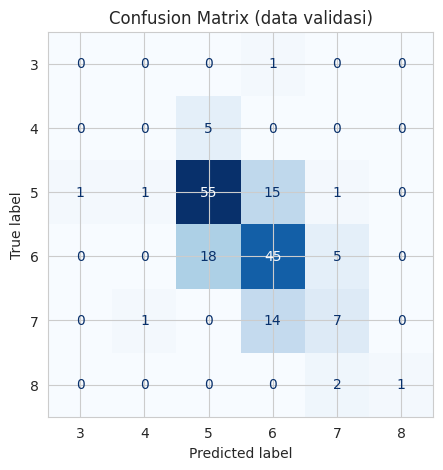

In [13]:
y_pred = best_model.predict(X_val)
print("Accuracy :", round(accuracy_score(y_val, y_pred), 4))
print("Macro-F1 :", round(f1_score(y_val, y_pred, average="macro"), 4))
print()
print(classification_report(y_val, y_pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_val, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (data validasi)")
plt.show()

**Interpretasi:** Model mencapai accuracy 0,6279 dan macro-F1 0,3727 pada data validasi (172 baris). Kelas mayoritas diprediksi paling baik: kelas 5 (precision 0,71; recall 0,75; F1 0,73) dan kelas 6 (0,60; 0,66; F1 0,63). Kelas 7 sedang (F1 0,38; recall 0,32). Kelas 3 dan 4 tidak ada yang terprediksi benar (F1 0,00; contoh validasinya hanya 1 dan 5 baris). Kelas 8 mendapat precision 1,00 tetapi recall 0,33, artinya 1 dari 3 sampel terdeteksi.
Karena contoh kelas minoritas sangat sedikit, hasil metriknya tidak stabil. Ini keterbatasan data, bukan semata kesalahan model. Perhatikan juga confusion matrix: kesalahan prediksi umumnya jatuh ke kelas bertetangga (misalnya 5 vs 6), yang wajar karena skor kualitas bersifat ordinal dan penilaian ahli subjektif.

### Feature importance

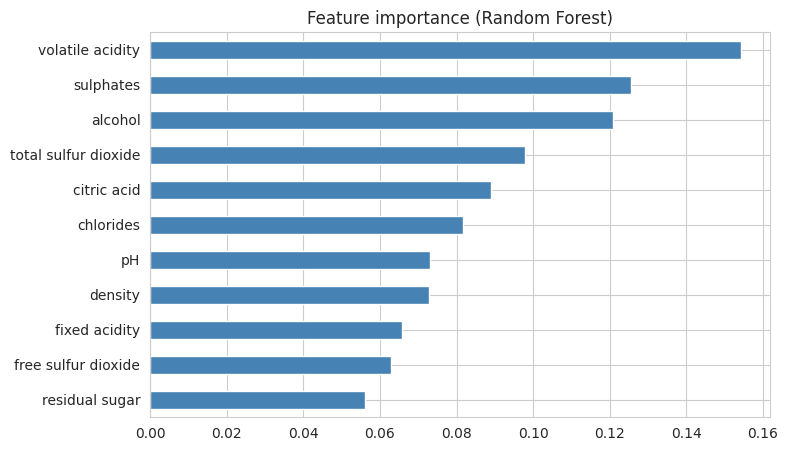

volatile acidity        0.1542
sulphates               0.1256
alcohol                 0.1208
total sulfur dioxide    0.0980
citric acid             0.0890
chlorides               0.0818
pH                      0.0732
density                 0.0728
fixed acidity           0.0658
free sulfur dioxide     0.0629
residual sugar          0.0561
dtype: float64


In [14]:
rf_final = best_model.named_steps["clf"]
imp = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("Feature importance (Random Forest)")
plt.show()
print(imp.sort_values(ascending=False).round(4))

**Interpretasi:** Fitur dengan importance tertinggi adalah volatile acidity (0,154), sulphates (0,126), dan alcohol (0,121), diikuti total sulfur dioxide (0,098) dan citric acid (0,089). Selisih tiga teratas kecil, jadi ketiganya berperan hampir setara. residual sugar (0,056) dan free sulfur dioxide (0,063) paling kecil kontribusinya.
Importance hanya menunjukkan besar pengaruh, bukan arahnya. Arahnya dapat dilihat dari korelasi: alcohol dan sulphates berkorelasi positif dengan kualitas, sedangkan volatile acidity negatif. Ini masuk akal secara kimiawi, karena keasaman volatil yang tinggi memberi rasa seperti cuka dan menurunkan kualitas.

## 5. Penyimpanan Model
Setelah hyperparameter terbaik ditemukan, model dilatih ulang menggunakan **seluruh** data training agar memakai semua informasi yang tersedia, lalu disimpan.

In [15]:
final_model = Pipeline([("scaler", StandardScaler()),
                        ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                **{k.replace("clf__", ""): v for k, v in search.best_params_.items()}))])
final_model.fit(X, y)

joblib.dump({"model": final_model, "features": FEATURES}, "model_wine.joblib")
print("Model tersimpan: model_wine.joblib")

Model tersimpan: model_wine.joblib


In [20]:
print("Model dipakai :", type(final_model.named_steps["clf"]).__name__)
print("Parameter     :", final_model.named_steps["clf"].get_params()["n_estimators"],
      "pohon | max_depth =", final_model.named_steps["clf"].max_depth,
      "| class_weight =", final_model.named_steps["clf"].class_weight)

Model dipakai : RandomForestClassifier
Parameter     : 200 pohon | max_depth = 30 | class_weight = balanced


## 6. Deployment: Prediksi Data Uji
Model dimuat ulang dari file, lalu dipakai memprediksi `data_testing.csv`.

In [18]:
bundle = joblib.load("model_wine.joblib")
loaded_model, feats = bundle["model"], bundle["features"]

# Cari kolom Id di data testing (abaikan huruf besar/kecil & spasi)
test.columns = test.columns.str.strip()
test_id = next(c for c in test.columns if c.lower() == "id")

pred = loaded_model.predict(test[feats]).astype(int)

# Baca file format (pemisah , atau ; terdeteksi otomatis)
try:
    fmt = pd.read_csv(PATH_FORMAT, sep=None, engine="python", encoding="utf-8-sig")
    fmt.columns = fmt.columns.str.strip()
    id_name = next(c for c in fmt.columns if c.lower() == "id")
    q_name  = next(c for c in fmt.columns if c.lower() == "quality")
except Exception as e:
    print("File format tidak terbaca, pakai nama kolom default. Penyebab:", e)
    fmt, id_name, q_name = None, "Id", "Quality"

hasil = pd.DataFrame({id_name: test[test_id].values, q_name: pred})

if fmt is not None:
    print("Id sama dengan file format :", set(hasil[id_name]) == set(fmt[id_name]))
    print("Jumlah baris sama          :", len(hasil) == len(fmt))
    hasil = fmt[[id_name]].merge(hasil, on=id_name, how="left")  # samakan urutan dengan format

out_name = f"hasilprediksi_{NIM3}.csv"
hasil.to_csv(out_name, index=False)
print("Disimpan:", out_name, hasil.shape)
display(hasil.head())
print(hasil[q_name].value_counts().sort_index())

Id sama dengan file format : True
Jumlah baris sama          : True
Disimpan: hasilprediksi_012.csv (286, 2)


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,6


Quality
4      1
5    127
6    124
7     33
8      1
Name: count, dtype: int64


**Interpretasi:** File hasilprediksi_012.csv berisi 286 baris dan 2 kolom (Id dan Quality), dengan Id dan jumlah baris sesuai file format. Distribusi prediksi: kelas 5 sebanyak 127, kelas 6 sebanyak 124, kelas 7 sebanyak 33, serta kelas 4 dan 8 masing-masing 1. Pola ini mirip distribusi training (didominasi kelas 5 dan 6), dan tidak ada prediksi kelas 3.

## 7. Kesimpulan
- Data tidak memiliki / memiliki missing value (0 di training dan testing) dan fitur berskala sangat berbeda sehingga digunakan `StandardScaler` dalam Pipeline.
- Baris duplikat **tidak dihapus**; jumlahnya hanya dicek (isi sesuai output).
- Distribusi kelas quality tidak seimbang (kelas 5 dan 6 sekitar 82%), sehingga evaluasi memakai accuracy dan macro-F1.
- Model terbaik: Random Forest Balanced hasil tuning (200 pohon, max_depth 30, class_weight balanced), dengan accuracy validasi 0.6279 dan macro-F1 0.3727.
- Fitur paling berpengaruh: volatile acidity (0.154), sulphates (0.126), dan alcohol (0.121), disusul total sulfur dioxide (0.098) dan citric acid (0.089).
- Keterbatasan: kelas minoritas (3, 4, 8) sulit diprediksi karena contohnya sangat sedikit. Ke depan bisa dicoba SMOTE, XGBoost/LightGBM, atau pendekatan ordinal.